In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder

In [35]:
df = pd.read_csv('AmesHousing.csv', compression='zip', encoding='latin-1')
print(df.shape)
df.head()

(2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [36]:
print(df.shape)
print(f"\nTarget column (SalePrice) stats:")
print(df['SalePrice'].describe())
print(f"\nColumns with most missing values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

(2930, 82)

Target column (SalePrice) stats:
count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64

Columns with most missing values:
Pool QC           2917
Misc Feature      2824
Alley             2732
Fence             2358
Mas Vnr Type      1775
Fireplace Qu      1422
Lot Frontage       490
Garage Qual        159
Garage Yr Blt      159
Garage Cond        159
Garage Finish      159
Garage Type        157
Bsmt Exposure       83
BsmtFin Type 2      81
Bsmt Qual           80
dtype: int64


In [37]:
# Drop columns with too many missing values (>50%)
threshold = len(df) * 0.5
df = df.dropna(thresh=threshold, axis=1)

# Fill remaining numeric nulls with median
numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# Fill categorical nulls with 'None'
cat_cols = df.select_dtypes(include=['object']).columns
df[cat_cols] = df[cat_cols].fillna('None')

# Encode categorical columns
le = LabelEncoder()
for col in cat_cols:
    df[col] = le.fit_transform(df[col])

print(f"Shape after cleaning: {df.shape}")

Shape after cleaning: (2930, 77)


In [38]:
X = df.drop('SalePrice', axis=1)
y = df['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = Ridge(alpha=10)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² Score : {r2:.4f}")
print(f"RMSE     : ${rmse:,.0f}")

R² Score : 0.8610
RMSE     : $33,384


/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.19857e-19): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


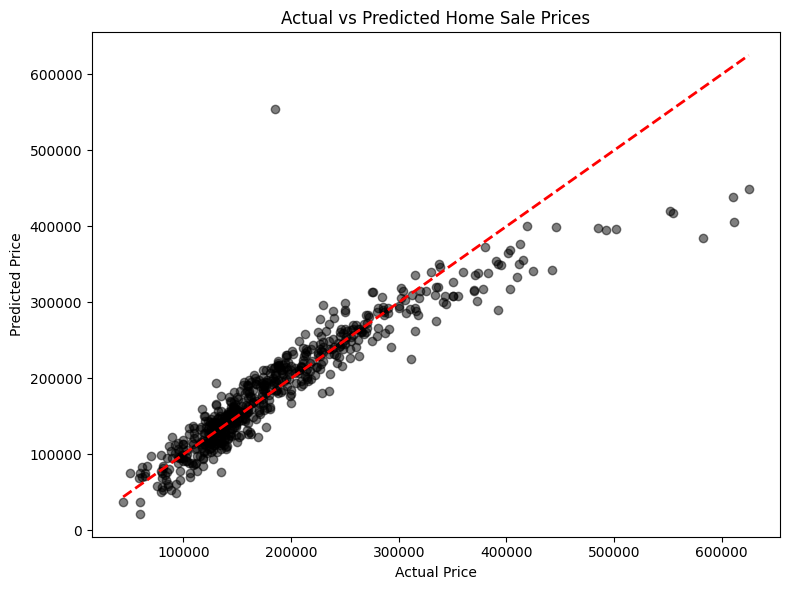

In [39]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5, color='black')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Home Sale Prices')
plt.tight_layout()
plt.show()

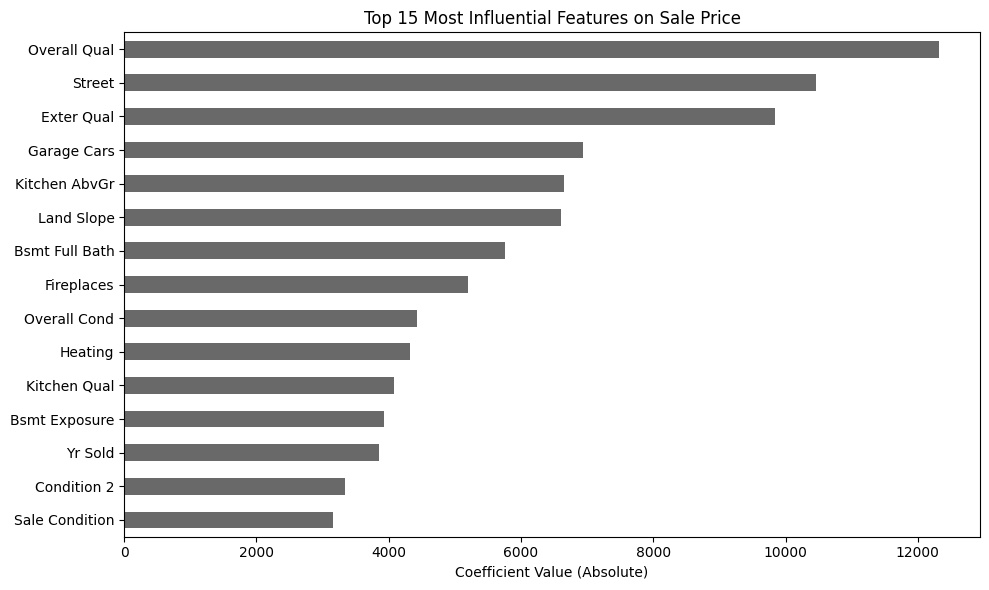

In [40]:
importance = pd.Series(model.coef_, index=X.columns)
top_features = importance.abs().sort_values(ascending=False).head(15)

plt.figure(figsize=(10,6))
top_features.sort_values().plot(kind='barh', color='dimgray')
plt.title('Top 15 Most Influential Features on Sale Price')
plt.xlabel('Coefficient Value (Absolute)')
plt.tight_layout()
plt.show()

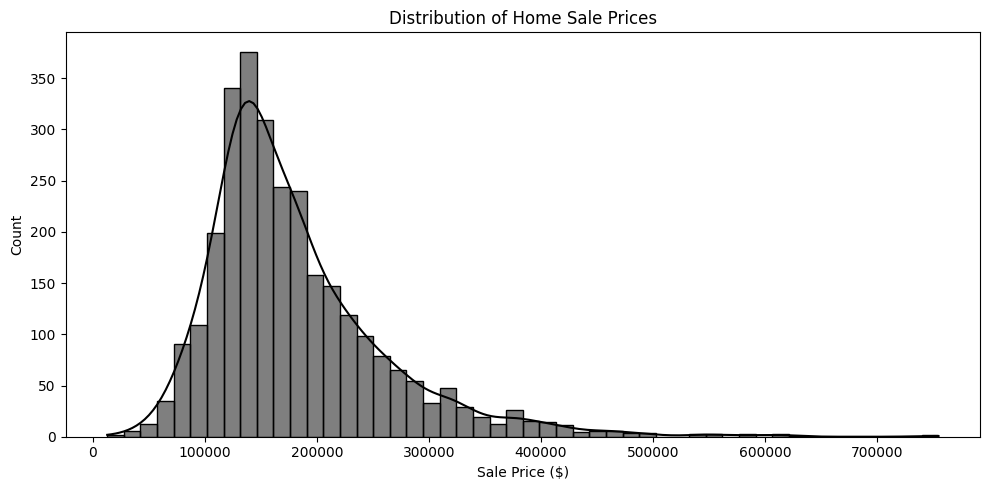

In [41]:
plt.figure(figsize=(10,5))
sns.histplot(df['SalePrice'], bins=50, color='black', kde=True)
plt.title('Distribution of Home Sale Prices')
plt.xlabel('Sale Price ($)')
plt.tight_layout()
plt.show()

In [42]:
avg_price = df['SalePrice'].mean()
max_price = df['SalePrice'].max()
min_price = df['SalePrice'].min()

top_features = pd.Series(model.coef_, index=X.columns).abs().sort_values(ascending=False).head(5).index.tolist()

print("=" * 50)
print("HOUSING PRICE PREDICTION — KEY FINDINGS")
print("=" * 50)
print(f"Dataset:        {df.shape[0]} homes, {df.shape[1]-1} features")
print(f"Model:          Ridge Regression (alpha=10)")
print(f"R² Score:       0.8610")
print(f"RMSE:           $33,384")
print(f"Avg Sale Price: ${avg_price:,.0f}")
print(f"Price Range:    ${min_price:,.0f} – ${max_price:,.0f}")
print(f"Top Features:   {', '.join(top_features[:3])}")
print("=" * 50)

HOUSING PRICE PREDICTION — KEY FINDINGS
Dataset:        2930 homes, 76 features
Model:          Ridge Regression (alpha=10)
R² Score:       0.8610
RMSE:           $33,384
Avg Sale Price: $180,796
Price Range:    $12,789 – $755,000
Top Features:   Overall Qual, Street, Exter Qual
